In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers,models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense

In [4]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=10000
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (25000,)
Testing data: (25000,)


In [5]:
max_length = 200

x_train = pad_sequences(x_train, maxlen=max_length)
x_test = pad_sequences(x_test, maxlen=max_length)

In [6]:
model=tf.keras.Sequential([
    layers.Embedding(10000,32,mask_zero=True),
    layers.SimpleRNN(32),
    layers.Dense(1,activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history=model.fit(x_train,y_train,epochs=5,batch_size=64,
                  validation_split=0.1)

loss,acc=model.evaluate(x_test,y_test)

print("RNN Accuracy:",acc)

Epoch 1/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - accuracy: 0.7085 - loss: 0.5542 - val_accuracy: 0.8096 - val_loss: 0.4331
Epoch 2/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8631 - loss: 0.3286 - val_accuracy: 0.8352 - val_loss: 0.3831
Epoch 3/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 36s 104ms/step - accuracy: 0.9119 - loss: 0.2257 - val_accuracy: 0.8492 - val_loss: 0.3769
Epoch 4/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 25s 57ms/step - accuracy: 0.9522 - loss: 0.1335 - val_accuracy: 0.8556 - val_loss: 0.4079
Epoch 5/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - accuracy: 0.9779 - loss: 0.0710 - val_accuracy: 0.7720 - val_loss: 0.5975
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.7779 - loss: 0.5889
RNN Accuracy: 0.7779200077056885


In [7]:
lstm_model=tf.keras.Sequential([
    layers.Embedding(10000,32,mask_zero=True),
    layers.LSTM(32),
    layers.Dense(1,activation='sigmoid')
])

lstm_model.compile(optimizer='adam',
                   loss='binary_crossentropy',
                   metrics=['accuracy'])

lstm_history=lstm_model.fit(x_train,y_train,epochs=5,batch_size=128,
                            validation_split=0.2)

loss,acc=lstm_model.evaluate(x_test,y_test)

print("LSTM Accuracy:",acc)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - accuracy: 0.7436 - loss: 0.5071 - val_accuracy: 0.8670 - val_loss: 0.3241
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - accuracy: 0.9000 - loss: 0.2595 - val_accuracy: 0.8696 - val_loss: 0.3244
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 105ms/step - accuracy: 0.9262 - loss: 0.1999 - val_accuracy: 0.8742 - val_loss: 0.3020
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - accuracy: 0.9497 - loss: 0.1465 - val_accuracy: 0.8682 - val_loss: 0.3380
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - accuracy: 0.9553 - loss: 0.1262 - val_accuracy: 0.8682 - val_loss: 0.3839
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8590 - loss: 0.4128
LSTM Accuracy: 0.858959972858429


In [8]:
gru_model=tf.keras.Sequential([
    layers.Embedding(10000,32,mask_zero=True),
    layers.GRU(32),
    layers.Dense(1,activation='sigmoid')
])

gru_model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

gru_history=gru_model.fit(x_train,y_train,epochs=5,batch_size=128,
                          validation_split=0.2)

loss,acc=gru_model.evaluate(x_test,y_test)

print("GRU Accuracy:",acc)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - accuracy: 0.6902 - loss: 0.5645 - val_accuracy: 0.8238 - val_loss: 0.4126
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - accuracy: 0.8770 - loss: 0.3003 - val_accuracy: 0.8708 - val_loss: 0.3161
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - accuracy: 0.9179 - loss: 0.2148 - val_accuracy: 0.8732 - val_loss: 0.3153
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.9351 - loss: 0.1762 - val_accuracy: 0.8682 - val_loss: 0.3334
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 127ms/step - accuracy: 0.9491 - loss: 0.1434 - val_accuracy: 0.8696 - val_loss: 0.3660
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8572 - loss: 0.3972
GRU Accuracy: 0.8571599721908569


782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7779 - loss: 0.5889
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8590 - loss: 0.4128
782/782 ━━━━━━━━━━━━━━━━━━━━ 27s 34ms/step - accuracy: 0.8572 - loss: 0.3972


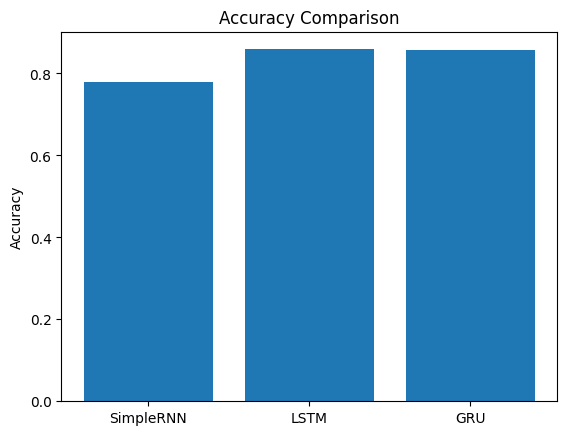

In [10]:
plt.bar(['SimpleRNN','LSTM','GRU'],
        [model.evaluate(x_test,y_test)[1],
         lstm_model.evaluate(x_test,y_test)[1],
         gru_model.evaluate(x_test,y_test)[1]])

plt.title('Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()

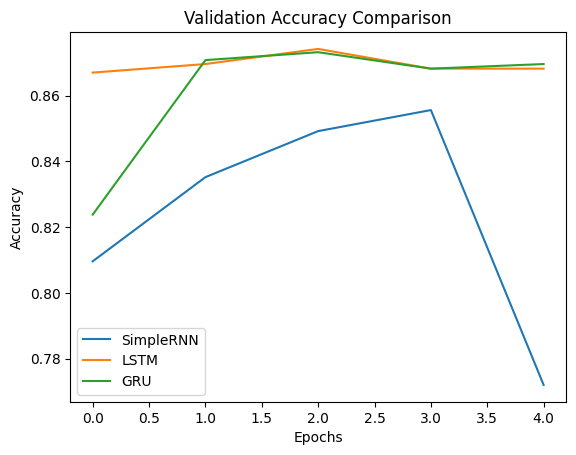

In [9]:
plt.plot(history.history['val_accuracy'],label='SimpleRNN')
plt.plot(lstm_history.history['val_accuracy'],label='LSTM')
plt.plot(gru_history.history['val_accuracy'],label='GRU')

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [41]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence
rev=input("Enter :")
word_index=imdb.get_word_index()
s=[1]
words=text_to_word_sequence(rev)
for i in words:
    index=word_index.get(i,2)
    if index!=2:
        index+=3
    if index>=10000:
        index=2
    s.append(index)
s=pad_sequences([s],maxlen=200)
pred=gru_model.predict(s)
pred=pred[0][0]
if(pred>=0.5):
    print("Positive",pred,"%")
else:
    print("Negative",(1-pred),"%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Positive 0.7818943 %
